# Этап 1: Инициализация проекта и загрузка данных

Файл `01_download_ecg_datasets.ipynb` представляет собой **первый технический ноутбук** в рамках комплексного проекта по разработке нейросетевого алгоритма детекции и классификации нарушений ритма сердца.

### Основное назначение
Главная задача этого модуля — разовое создание воспроизводимой структуры проекта на *Google Drive* и автоматизированная загрузка открытых ЭКГ-датасетов. Набор этих данных сформирует надежный фундамент для всех последующих этапов пайплайна:

* **Анализ разметки** — первичный аудит исходных метаданных и аннотаций.
* **Harmonization меток** — приведение разнородных классов и меток датасетов к единому стандарту.
* **Обучение моделей** — тренировка базовых и кастомных архитектур нейросетей.
* **Внешняя валидация** — независимое тестирование качества работы алгоритмов.
* **Beat-level эксперименты** — локальный анализ ЭКГ на уровне отдельных сердечных комплексов.
* **Сравнительный анализ** — сопоставление эффективности классических ML-методов и Deep Learning подходов.

---

### Границы ответственности (Scope)

* **Что делает ноутбук:**
  * Автоматически разворачивает дерево директорий проекта.
  * Настраивает зависимости окружения.
  * Скачивает, верифицирует и распаковывает raw-данные.
  * Выполняет первичную проверку целостности загруженных файлов.


  **Сразу уточню название:** Chapman — это сокращённое название базы, связанное с Chapman University и Shaoxing People’s Hospital, а не название сигарет. Полное название — A large scale 12-lead electrocardiogram database for arrhythmia study.

## Подключение к диску

Что происходит:

- Colab запрашивает разрешение на доступ к Google Drive.

- После подтверждения Drive становится доступен по пути /content/drive.

- Все данные проекта будут сохраняться в MyDrive/ECG_Project.

Возможные проблемы:

- не появляется окно авторизации — проверить блокировщики всплывающих окон;

- выбран не тот Google-аккаунт — перемонтировать Drive;

- Colab просит перезапустить runtime — перезапустить и выполнить ячейку снова.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


# Спецификация данных проекта: загрузка и требования к памяти

Ниже приведен список датасетов, загружаемых для проекта, их роль и требования к свободному дисковому пространству.

### Список скачиваемых датасетов

| Датасет | PhysioNet path | Роль в проекте | Примерный размер после распаковки |
| :--- | :--- | :--- | :--- |
| **Chapman** | `ecg-arrhythmia/1.0.0` | Основной baseline / training | ~5.1 GB |
| **PTB-XL** | `ptb-xl/1.0.3` | External validation / harmonization labels | ~3.0 GB |
| **INCART** | `incartdb/1.0.0` | External validation / long-record analysis | ~0.8 GB |
| **MIT-BIH** | `mitdb/1.0.0` | Beat-level arrhythmia detection | ~0.1 GB |
| **Итого** | — | — | **~9.0 GB (только raw-данные)** |

---

### Требования к дисковому пространству

> ⚠️ **Важная рекомендация:** Необходимо иметь **15–20 GB** свободного места на *Google Drive*.

Помимо исходных (raw) данных, свободное место потребуется под генерацию следующих артефактов:
* **Processed data** — обработанные и очищенные данные.
* **Numpy arrays** — сконвертированные массивы для быстрой загрузки в модель.
* **Промежуточные файлы** — временные кэши и метаданные.
* **Модели и checkpoints** — сохраненные веса нейросетей в процессе обучения.
* **Результаты экспериментов** — логи, отчеты и сгенерированные графики.


## Почему не скачивается Challenge 2020?

> 💡 **Краткий ответ:** Датасет **Challenge 2020** сознательно не добавляется на текущем этапе проекта. Его интеграция отложена до завершения полного аудита основных данных.

### Структурный состав Challenge 2020
Этот датасет является составным и уже включает в себя как те данные, которые мы качаем отдельно, так и новые базы:
* **Пересекающиеся источники:** `PTB-XL` и `INCART` (уже есть в основном списке).
* **Новые источники:** `CPSC`, `PTB` и `Georgia`.

---

### Критические риски при ранней загрузке

Если скачать Challenge 2020 прямо сейчас, возникнут следующие проблемы:

1. **Дублирование источников** — одни и те же записи будут занимать лишнее место в разных папках.
2. **Утечка данных (Data Leakage)** — из-за дублей одни и те же пациенты могут одновременно попасть в *train*, *validation* и *test*, что исказит метрики модели.
3. **Путаница при гармонизации меток** — разметка одних и тех же ЭКГ-сигналов в разных источниках может конфликтовать.
4. **Неконтролируемый рост проекта** — размер директории превысит выделенные лимиты Google Drive.

### Дальнейшие шаги
Использование **Challenge 2020** можно будет рассмотреть позже в качестве **отдельного эксперимента**. Это станет возможным только после того, как мы настроим и проведем аудит текущего базового набора датасетов.


## Создание структуры проекта

Что происходит:

- создаётся корневая папка ECG_Project;

- создаются подпапки для данных, ноутбуков, исходного кода и отчётов;

- создаются отдельные папки под каждый raw-датасет.

In [2]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/ECG_detection")

DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_DIR / "external"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
SRC_DIR = PROJECT_ROOT / "src"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Dataset directories
CHAPMAN_DIR = RAW_DIR / "chapman"
PTBXL_DIR = RAW_DIR / "ptbxl"
INCART_DIR = RAW_DIR / "incart"
MITBIH_DIR = RAW_DIR / "mitbih"

# Create directories
directories = [
    PROJECT_ROOT,
    DATA_DIR,
    RAW_DIR,
    PROCESSED_DIR,
    EXTERNAL_DIR,
    NOTEBOOKS_DIR,
    SRC_DIR,
    REPORTS_DIR,
    CHAPMAN_DIR,
    PTBXL_DIR,
    INCART_DIR,
    MITBIH_DIR,
]

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

print("ECG project structure created:")
print(PROJECT_ROOT)

ECG project structure created:
/content/drive/MyDrive/ECG_detection


## Предварительные требования

Перед запуском ноутбука необходимо выполнить следующие условия и подготовить рабочее окружение.

### Обязательные требования
* **Google-аккаунт** — активная учетная запись для доступа к облачным сервисам.
* **Google Colab** — среда выполнения, в которой должен быть открыт проект.
* **Имя ноутбука** — создайте новый файл со строгим названием `01_download_ecg_datasets.ipynb`.
* **Свободное место** — убедитесь, что на вашем *Google Drive* достаточно дискового пространства.
* **Стабильный интернет** — критически важен для непрерывной скачки больших архивов.
* **Активная вкладка** — не закрывайте вкладку браузера с запущенным Colab до окончания процесса.
* **Запас времени** — учитывайте, что загрузка тяжелых датасетов (`Chapman` и `PTB-XL`) займет длительное время.

### Желательные рекомендации
* **Улучшенный runtime** — используйте *Colab Pro* или любой стабильный тип инстанса, если планируется долгая сессия.
* **Раздельный запуск** — не запускайте все загрузки одновременно, качайте данные последовательно.
* **Мониторинг сессии** — периодически проверяйте статус выполнения, чтобы runtime не отключился по таймауту.
* **Защита от обрывов** — при случайном разрыве соединения используйте флаг докачки `wget -c` (он уже интегрирован в скрипт функции).

---

## Итоговая структура проекта

После успешного выполнения кода из ноутбука в вашем облачном хранилище сформируется следующая архитектура каталогов:

```text
MyDrive/
└── ECG_Project/
    │
    ├── data/
    │   ├── raw/
    │   │   ├── chapman/
    │   │   │   └── physionet.org/files/ecg-arrhythmia/1.0.0/
    │   │   │       ├── WFDBRecords/
    │   │   │       ├── ConditionNames_SNOMED-CT.csv
    │   │   │       ├── LICENSE.txt
    │   │   │       ├── RECORDS
    │   │   │       └── SHA256SUMS.txt
    │   │   │
    │   │   ├── ptbxl/
    │   │   │   └── physionet.org/files/ptb-xl/1.0.3/
    │   │   │       ├── ptbxl_database.csv
    │   │   │       ├── scp_statements.csv
    │   │   │       ├── records100/
    │   │   │       └── records500/
    │   │   │
    │   │   ├── incart/
    │   │   │   └── physionet.org/files/incartdb/1.0.0/
    │   │   │
    │   │   └── mitbih/
    │   │       └── physionet.org/files/mitdb/1.0.0/
    │   │
    │   ├── processed/
    │   └── external/
    │
    ├── notebooks/
    ├── src/
    └── reports/
```

> ⚠️ **Важное примечание:** Внутри директории каждого датасета автоматически генерируется вложенный путь `physionet.org/files/...`. Это связано со спецификой работы утилиты `wget`, которая запускается локально из целевой папки и принудительно воссоздает исходную структуру URL-адресов сервера-источника.


## Проверка свободного места в Google Drive

Перед началом скачивания скрипт выполняет автоматическую проверку накопителя. Мы вручную или программно валидируем следующие метрики:
* **Общий объём** — общая емкость подключенного хранилища (Google Drive / локальный диск).
* **Занятое место** — текущий объем, уже используемый другими файлами.
* **Свободное место** — доступный остаток для развертывания проекта.

---

### ⚠️ Рекомендации по лимитам памяти

| Критерий | Требуемый объем | Назначение |
| :--- | :--- | :--- |
| **Критический минимум** | **~9 GB** | Исключительно под скачивание и распаковку исходных (raw) данных |
| **Рекомендуемый оптимум** | **15–20 GB** | С запасом под `processed data`, чекпоинты моделей, логи и графики |

> 💡 **Что делать при нехватке места:** Если по результатам проверки свободного пространства оказалось **меньше 15 GB**, настоятельно рекомендуется очистить корзину Google Drive, удалить старые тяжелые файлы или переключить runtime на другой Google-аккаунт с пустым диском. В противном случае загрузка прервется на середине из-за переполнения памяти.

In [3]:
import shutil

total, used, free = shutil.disk_usage("/content/drive/MyDrive")

print(f"Total space: {total / 1024**3:.2f} GB")
print(f"Used space:  {used / 1024**3:.2f} GB")
print(f"Free space:  {free / 1024**3:.2f} GB")

Total space: 15.00 GB
Used space:  8.32 GB
Free space:  6.68 GB


## Установка необходимых библиотек

Для корректной работы ноутбука и последующих этапов пайплайна требуется предустановить базовый стек библиотек. Ниже приведена спецификация ключевых инструментов:

| Библиотека | Назначение в проекте |
| :--- | :--- |
| **`wfdb`** | **Чтение специализированных WFDB-записей PhysioNet** (файлы `.hea`, `.dat`, `.atr`). Понадобится на протяжении всего проекта для низкоуровневой работы с ЭКГ. |
| **`pandas`** | Работа со структурированными данными: чтение метаданных, парсинг таблиц и маппинг меток (*labels*). |
| **`numpy`** | Быстрые численные и матричные операции над многомерными массивами ЭКГ-сигналов. |
| **`scipy`** | Цифровая обработка сигналов: фильтрация шумов, изоэлектрической линии и артефактов. |
| **`scikit-learn`** | Валидация: корректное разбиение данных (*split*), расчет классических метрик и ML-baseline. |
| **`tqdm`** | Визуализация интерактивных прогресс-баров при длительном скачивании и обработке файлов. |

---

> 🛠 **Важное примечание по `wfdb`:**  
Библиотека `wfdb` является сквозным инструментом. Она будет активно использоваться не только для первичной верификации данных на этапе загрузки, но и далее — при парсинге заголовков, извлечении частоты дискретизации и чтении разметки отведений.

In [4]:
!pip install -q wfdb pandas numpy scipy scikit-learn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.8 MB/s eta 0:00:00


## Проверяем подключение к Drive

In [5]:
from pathlib import Path

print("Project exists:", PROJECT_ROOT.exists())
print("Raw directory:", RAW_DIR.exists())
print("Chapman directory:", CHAPMAN_DIR.exists())
print("PTB-XL directory:", PTBXL_DIR.exists())
print("INCART directory:", INCART_DIR.exists())
print("MIT-BIH directory:", MITBIH_DIR.exists())

Project exists: True
Raw directory: True
Chapman directory: True
PTB-XL directory: True
INCART directory: True
MIT-BIH directory: True


Для автоматизации процесса загрузки используется функция, которая обращается к утилите `wget` через системный подпроцесс Python.

In [6]:
import subprocess
from pathlib import Path


def download_physionet(dataset_path, output_dir):
    """
    Download a PhysioNet dataset into Google Drive.

    Parameters
    ----------
    dataset_path : str
        PhysioNet path, e.g.
        'ecg-arrhythmia/1.0.0'

    output_dir : Path
        Destination directory in Google Drive.
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    url = f"https://physionet.org/files/{dataset_path}/"

    command = [
        "wget",
        "-r",
        "-N",
        "-c",
        "-np",
        url,
    ]

    print("=" * 70)
    print(f"Downloading:")
    print(url)
    print()
    print(f"Destination:")
    print(output_dir)
    print("=" * 70)

    subprocess.run(
        command,
        cwd=str(output_dir),
        check=True,
    )

    print("\nDownload completed.")

### 🛠 Разбор параметров утилиты `wget`

Команда настроена таким образом, чтобы загрузка больших объемов данных проходила максимально стабильно и предсказуемо:

| Параметр | Значение | Зачем это нужно в проекте |
| :---: | :--- | :--- |
| **`-r`** | Рекурсивное скачивание | Позволяет обойти дерево каталогов сервера и выкачать все вложенные файлы и папки. |
| **`-N`** | Проверка временных меток (*timestamps*) | Защищает от повторного скачивания. Если файл уже скачан и не менялся на сервере, `wget` его пропустит. |
| **`-c`** | Возобновление загрузки (*continue*) | Автоматически продолжает скачивание файла с места обрыва связи, экономя трафик и время. |
| **`-np`** | Без перехода в родительские каталоги (*no-parent*) | Гарантирует, что утилита пойдет только «вниз» по указанному URL и не начнет скачивать весь сайт PhysioNet. |

---

### ⚙️ Логика и ключевые шаги работы функции

1. **Создание инфраструктуры:** Принимает путь и автоматически создает целевую папку на *Google Drive* (включая все промежуточные каталоги благодаря `parents=True`), если она не существовала.
2. **Формирование URL:** На основе переданного пути к датасету (`dataset_path`) собирает прямую ссылку на файловый репозиторий PhysioNet.
3. **Изолированный запуск:** Запускает процесс `wget` строго внутри созданной целевой папки (`cwd=str(output_dir)`). Благодаря этому исходное дерево папок сервера разворачивается именно там, где нужно.
4. **Контроль ошибок:** Использование параметра `check=True` в `subprocess.run` гарантирует, что если скачивание завершится неудачей (например, пропадет сеть или закончится место), Python немедленно прервет выполнение ячейки и выбросит исключение `CalledProcessError`. Это предотвратит запуск последующих шагов на "битых" данных.

## Скачивание датасета Chapman

Начинаем процесс сбора данных с загрузки ключевого и самого емкого датасета.



In [ ]:
download_physionet(
    dataset_path="ecg-arrhythmia/1.0.0",
    output_dir=CHAPMAN_DIR,
)

Downloading:
https://physionet.org/files/ecg-arrhythmia/1.0.0/

Destination:
/content/drive/MyDrive/ECG_detection/data/raw/chapman

Download completed.


---

### 📊 Спецификация данных Chapman Dataset

* **Объем выборки** — более **45 000** уникальных записей ЭКГ.
* **Формат сигнала** — стандартные **12 отведений** для полной клинической картины.
* **Частота дискретизации** — **500 Hz** (обеспечивает высокую детализацию сигнала).
* **Размер архива** — около **2.3 GB** в сжатом (ZIP) виде.
* **Итоговый размер** — примерно **5.1 GB** дискового пространства после распаковки.

---

### 🎯 Почему Chapman загружается первым?

1. **Основной baseline** — этот датасет выбран в качестве фундаментального фундамента для обучения базовых моделей.
2. **Аудит меток (Label Audit)** — из-за высокой плотности данных на нем удобнее всего выстраивать пайплайны валидации разметки.
3. **Богатая аннотация** — содержит детализированный спектр аритмий и сочетанных нарушений проводимости.
4. **Фильтрация классов** — на основе анализа Chapman будет приниматься финальное архитектурное решение о том, какие именно классы патологий пойдут в итоговую модель.

---

### ⚠️ Важные инструкции на время выполнения ячейки

Поскольку загрузка более 2 ГБ данных в облачную сессию требует времени, строго соблюдайте следующие правила:
* **Сохраняйте активность** — не закрывайте вкладку браузера с Google Colab, чтобы предотвратить сброс сессии (*runtime disconnect*).
* **Не перегружайте сеть** — не отключайте интернет и не запускайте параллельно ячейки скачивания для остальных датасетов (`PTB-XL`, `INCART`, `MIT-BIH`). Скачивание должно идти строго последовательно.
* **Мониторьте память** — следите за тем, как уменьшается свободное место на Google Drive в процессе распаковки.

## Проверка структуры и целостности Chapman

После завершения загрузки необходимо выполнить первичную валидацию, чтобы убедиться, что все критически важные файлы датасета успешно скачались и находятся на своих местах.

In [7]:
CHAPMAN_ROOT = (
    CHAPMAN_DIR
    / "physionet.org"
    / "files"
    / "ecg-arrhythmia"
    / "1.0.0"
)

print("Chapman root:")
print(CHAPMAN_ROOT)

print("\nExists:", CHAPMAN_ROOT.exists())

if CHAPMAN_ROOT.exists():
    print("\nContents:")
    for item in CHAPMAN_ROOT.iterdir():
        print(item.name)

Chapman root:
/content/drive/MyDrive/ECG_detection/data/raw/chapman/physionet.org/files/ecg-arrhythmia/1.0.0

Exists: True

Contents:
ConditionNames_SNOMED-CT.csv
RECORDS
LICENSE.txt
SHA256SUMS.txt
index.html
WFDBRecords


---

### 📋 Ожидаемое содержимое директории (Чек-лист)

В консоли ноутбука должен отобразиться следующий список обязательных артефактов:
* `WFDBRecords` — каталог, содержащий непосредственно файлы ЭКГ-сигналов и заголовков.
* `ConditionNames_SNOMED-CT.csv` — таблица маппинга диагнозов и кодов медицинских концептов.
* `LICENSE.txt` — лицензионное соглашение PhysioNet.
* `RECORDS` — текстовый файл со списком всех доступных записей.
* `SHA256SUMS.txt` — контрольные суммы для проверки целостности файлов.
* *Примечание:* Также может присутствовать технический файл `index.html`, сгенерированный сервером при парсинге страниц.

---

### 🛠 План действий при обнаружении ошибок (Troubleshooting)

Если ячейка вывела `Exists: False` или в списке отсутствуют ключевые файлы/папки:

1. **Контроль завершения** — убедитесь, что предыдущая ячейка скачивания завершила работу со статусом `0`, а не упала по таймауту.
2. **Валидация путей** — перепроверьте корректность инициализации переменной `CHAPMAN_DIR` и общую структуру каталогов в Google Drive.
3. **Анализ логов `wget`** — проверьте консольный вывод на наличие ошибок сети (например, `403 Forbidden` или `Connection timed out`).
4. **Перезапуск с докачкой** — запустите **ячейку по скачиванию набора данных** повторно. Благодаря встроенному флагу `-c`, утилита `wget` не будет скачивать данные заново, а просто докачает недостающие или поврежденные фрагменты.

In [8]:
import pandas as pd

condition_file = CHAPMAN_ROOT / "ConditionNames_SNOMED-CT.csv"

conditions = pd.read_csv(condition_file)

print("Shape:", conditions.shape)

display(conditions)

Shape: (63, 3)


,Acronym Name,Full Name,Snomed_CT
0,1AVB,1 degree atrioventricular block,270492004
1,2AVB,2 degree atrioventricular block,195042002
2,2AVB1,2 degree atrioventricular block(Type one),54016002
3,2AVB2,2 degree atrioventricular block(Type two),28189009
4,3AVB,3 degree atrioventricular block,27885002
...,...,...,...
58,SVT,Supraventricular Tachycardia,426761007
59,AT,Atrial Tachycardia,713422000
60,AVNRT,Atrioventricular Node Reentrant Tachycardia,233896004
61,AVRT,Atrioventricular Reentrant Tachycardia,233897008


### Зачем это нужно:

- ConditionNames_SNOMED-CT.csv содержит соответствие между SNOMED-CT кодами и названиями состояний;

- это ключевой файл для анализа разметки;

- на его основе позже будет строиться label audit;

- мы не должны вручную решать, какие классы брать, пока не посмотрим исходную разметку.

In [ ]:
records_file = CHAPMAN_ROOT / "RECORDS"

with open(records_file, "r") as f:
    records = [line.strip() for line in f if line.strip()]

print("Number of records:", len(records))
print("\nFirst 20 records:")

for record in records[:46]:
    print(record)

Number of records: 452

First 20 records:
WFDBRecords/01/010/
WFDBRecords/01/011/
WFDBRecords/01/012/
WFDBRecords/01/013/
WFDBRecords/01/014/
WFDBRecords/01/015/
WFDBRecords/01/016/
WFDBRecords/01/017/
WFDBRecords/01/018/
WFDBRecords/01/019/
WFDBRecords/02/020/
WFDBRecords/02/021/
WFDBRecords/02/022/
WFDBRecords/02/023/
WFDBRecords/02/024/
WFDBRecords/02/025/
WFDBRecords/02/026/
WFDBRecords/02/027/
WFDBRecords/02/028/
WFDBRecords/02/029/
WFDBRecords/03/030/
WFDBRecords/03/031/
WFDBRecords/03/032/
WFDBRecords/03/033/
WFDBRecords/03/034/
WFDBRecords/03/035/
WFDBRecords/03/036/
WFDBRecords/03/037/
WFDBRecords/03/038/
WFDBRecords/03/039/
WFDBRecords/04/040/
WFDBRecords/04/041/
WFDBRecords/04/042/
WFDBRecords/04/043/
WFDBRecords/04/044/
WFDBRecords/04/045/
WFDBRecords/04/046/
WFDBRecords/04/047/
WFDBRecords/04/048/
WFDBRecords/04/049/
WFDBRecords/05/050/
WFDBRecords/05/051/
WFDBRecords/05/052/
WFDBRecords/05/053/
WFDBRecords/05/054/
WFDBRecords/05/055/


## Скачивание PTB-XL
PTB-XL занимает около 3 GB после распаковки, ZIP — около 1.7 GB. В нём есть ptbxl_database.csv, scp_statements.csv, records100 и records500.

In [ ]:
download_physionet(
    dataset_path="ptb-xl/1.0.3",
    output_dir=PTBXL_DIR,
)

Downloading:
https://physionet.org/files/ptb-xl/1.0.3/

Destination:
/content/drive/MyDrive/ECG_detection/data/raw/ptbxl

Download completed.


Смотрим что находится внутри:

In [9]:
PTBXL_ROOT = (
    PTBXL_DIR
    / "physionet.org"
    / "files"
    / "ptb-xl"
    / "1.0.3"
)

print("PTB-XL root:")
print(PTBXL_ROOT)

print("\nContents:")

for item in PTBXL_ROOT.iterdir():
    print(item.name)

PTB-XL root:
/content/drive/MyDrive/ECG_detection/data/raw/ptbxl/physionet.org/files/ptb-xl/1.0.3

Contents:
records100
scp_statements.csv
example_physionet.py
ptbxl_v102_changelog.txt
RECORDS
ptbxl_v103_changelog.txt
ptbxl_database.csv
LICENSE.txt
SHA256SUMS.txt
index.html
records500


In [10]:
ptbxl_database = pd.read_csv(
    PTBXL_ROOT / "ptbxl_database.csv"
)

scp_statements = pd.read_csv(
    PTBXL_ROOT / "scp_statements.csv"
)

print("ptbxl_database:", ptbxl_database.shape)
print("scp_statements:", scp_statements.shape)

display(ptbxl_database.head())

ptbxl_database: (21799, 28)
scp_statements: (71, 13)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [11]:
display(scp_statements.head())

,Unnamed: 0,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
0,NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
1,NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
2,DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
3,LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
4,NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


## INCART

INCART содержит 75 получасовых 12-lead записей из 32 Holter records, частота 257 Hz; в headers есть идентификатор пациента/исходной Holter-записи. Распакованный размер — около 794.5 MB.

Именно поэтому INCART нам особенно интересен для external validation и long-record analysis, а не как основной training dataset.

In [12]:
download_physionet(
    dataset_path="incartdb/1.0.0",
    output_dir=INCART_DIR,
)

Downloading:
https://physionet.org/files/incartdb/1.0.0/

Destination:
/content/drive/MyDrive/ECG_detection/data/raw/incart

Download completed.


## MIT-BIH

MIT-BIH существенно меньше — около 104 MB после распаковки. Он содержит ECG с beat annotations и подходит для отдельного эксперимента по beat-level arrhythmia detection.


In [13]:
download_physionet(
    dataset_path="mitdb/1.0.0",
    output_dir=MITBIH_DIR,
)

Downloading:
https://physionet.org/files/mitdb/1.0.0/

Destination:
/content/drive/MyDrive/ECG_detection/data/raw/mitbih

Download completed.


## Финальная проверка размеров

Фактические цифры могут немного отличаться из-за служебных файлов.

In [14]:
def directory_size_gb(path):
    total = 0

    for file in Path(path).rglob("*"):
        if file.is_file():
            total += file.stat().st_size

    return total / (1024 ** 3)


datasets = {
    "Chapman": CHAPMAN_DIR,
    "PTB-XL": PTBXL_DIR,
    "INCART": INCART_DIR,
    "MIT-BIH": MITBIH_DIR,
}

for name, path in datasets.items():
    if path.exists():
        print(f"{name:10s}: {directory_size_gb(path):.2f} GB")
    else:
        print(f"{name:10s}: NOT FOUND")

Chapman   : 5.09 GB
PTB-XL    : 2.97 GB
INCART    : 0.78 GB
MIT-BIH   : 0.10 GB


А **Challenge 2020** пока сознательно не скачиваем. Он содержит в том числе PTB-XL и INCART вместе с CPSC, PTB и Georgia, поэтому добавление его сейчас создаст ненужный риск дублирования источников. В материалах Challenge 2020 действительно указаны PTB-XL, INCART, CPSC, PTB и Georgia как составляющие набора.

## Обоснование архитектуры данных и последовательности этапов

Стратегия развития проекта разделена на четыре последовательных базовых этапа и одну выделенную исследовательскую ветку. Это позволяет планомерно наращивать сложность моделей и защищает инфраструктуру от хаоса.

### 🗺 Поэтапный план реализации

#### **Этап 1 — Инициализация и базовый аудит (Chapman–Shaoxing)**
* **Воспроизведение результатов:** Полное повторение метрик оригинальных разработчиков для фиксации отправной точки.
* **Глубокий анализ данных:** Валидация всех меток разметки, выявление и разбор смешанных диагнозов.
* **Борьба с дисбалансом:** Оценка распределения классов патологий.
* **Валидация разбиения:** Настройка строгого разделения выборок (*train/val/test*) исключительно по пациентам (Patient-wise split) для исключения утечек.

#### **Этап 2 — Гармонизация и расширение (PTB-XL)**
* **Согласование меток:** Кропотливый маппинг и проверка возможности расширения итогового пула классов.
* **Внешнее тестирование:** Проведение первичного внешнего теста (*external validation*) на пересекающихся, базовых категориях патологий.
* **Защита от искажений:** Категорический запрет на автоматическое объединение концептуально несовместимых меток разметки.

#### **Этап 3 — Специфическая валидация (INCART и MIT-BIH)**
* **INCART:** Оценка устойчивости и качества работы моделей на длительных записях сигналов.
* **MIT-BIH Arrhythmia:** Использование датасета строго как изолированного бенчмарка микро-уровня (*beat-level benchmark*).
* **Ограничение:** Запрещено рассматривать данные холтеровского мониторинга как прямую замену коротким стандартным 12-канальным ЭКГ.

#### **Этап 4 — Исследование желудочковых тахикардий (VT)**
* **Подключение VFDB:** Детальное изучение и разметка непрерывных эпизодов желудочковой тахикардии и фибрилляции желудочков (VT/VF).
* **Подключение VTaC:** Анализ истинных и ложных срабатываний (алармов) при желудочковой тахикардии.
* **Методология:** Выделение этих задач в обособленные суб-проекты со своими изолированными протоколами оценки метрик.

#### **Этап 5 — Синтетическая генерация и балансировка**
* **Фиксация baseline:** Любые эксперименты с генерацией начинаются только после получения стабильного классического baseline на реальных данных.
* **Сравнительный анализ:** Прямое сопоставление классических методов балансировки классов, продвинутой аугментации сигналов (`augmentation`) и условных генеративно-состязательных сетей (`conditional GAN`).
* **Оптимизация:** Переход к сложным архитектурам `VAE` и диффузионным моделям (`diffusion`) откладывается до момента, пока в них не возникнет обоснованная архитектурная необходимость.

---

### 🔀 Итоговая архитектурная рекомендация

Проект реализует **гибридный подход**: мы сохраняем классический линейный пайплайн для многоклассового классификатора, но параллельно запускаем R&D-ветку для экстремальных патологий.

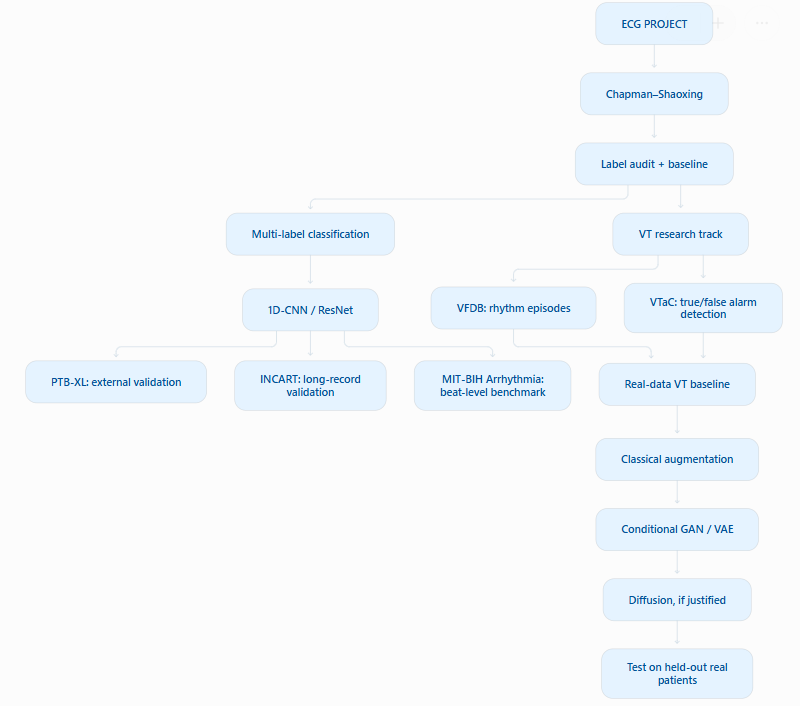

> ⚠️ **Главный вывод:** Такая схема позволяет непрерывно развивать базовую модель классификации и параллельно глубоко изучать редкие, критические для жизни аритмии, полностью исключая смешивание несовместимых типов медицинской разметки.

---

### 🛡 Железное правило дата-инжиниринга проекта

```text
⛔ КАТЕГОРИЧЕСКИ ЗАПРЕЩЕНО скачивать любую новую базу данных до тех пор, пока:
  1. Четко и однозначно не сформулирована конкретная гипотеза, которую эта база поможет проверить.
  2. Полностью не определен математический протокол оценки финального результата.
```
*Это — единственный и самый эффективный способ защитить инфраструктуру разработки и Google Drive от превращения в неструктурированную свалку терабайтных архивов.*

